# Investigating specificity information in AF3 Scores

In this notebook, we investigate the ability of alphafold3 confidence scores at discriminating between binding and non-binding TCR:pMHC complexes.

In [1]:
import glob
import json
import os
import re

import anarci
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ranksums
from sklearn.metrics import roc_auc_score

from tcr_pmhc_predicted_structures.utils import (
    IMGT_CDR,
    IMGT_MHC_TCR_CONTACT_POSITIONS,
    MHC_I_IMGT_BETA_HELIX_START,
)

In [2]:
CHAIN_ORDER = ('mhc_chain_1', 'mhc_chain_2', 'antigen_chain', 'alpha_chain', 'beta_chain')

In [3]:
af3_scores = []

for path in glob.glob('../data/interim/structures-af3/*/seed-*_sample-*/*_summary_confidences.json'):
    with open(path) as fh:
        summary_confidences = json.load(fh)

    name = re.match(
        r'(?P<structure_name>\d+(?:_\d+)?)_seed-(?P<seed>\d+)_sample-(?P<sample>\d+)_summary_confidences.json',
        os.path.basename(path),
    )

    score = {
        **name.groupdict(),
        **{key: val for key, val in summary_confidences.items() if not isinstance(val, list)},
    }

    for chain_name, chain_ptm in zip(CHAIN_ORDER, summary_confidences['chain_ptm'], strict=True):
        score[chain_name + '_ptm'] = chain_ptm

    for chain_name, chain_ptm in zip(CHAIN_ORDER, summary_confidences['chain_iptm'], strict=True):
        score[chain_name + '_iptm'] = chain_ptm

    for i, (chain_name_1, chain_iptms) in enumerate(
        zip(CHAIN_ORDER, summary_confidences['chain_pair_iptm'], strict=True)
    ):
        for chain_name_2, iptm in zip(CHAIN_ORDER[i + 1 :], chain_iptms[i + 1 :], strict=True):
            if chain_name_1 != chain_name_2:
                score[chain_name_1 + '_' + chain_name_2 + '_iptm'] = iptm

    for chain_name_1, chain_pae_min in zip(CHAIN_ORDER, summary_confidences['chain_pair_pae_min'], strict=True):
        for chain_name_2, pae_min in zip(CHAIN_ORDER, chain_pae_min, strict=True):
            score[chain_name_1 + '_' + chain_name_2 + '_pae_min'] = pae_min

    af3_scores.append(score)

af3_scores = pd.DataFrame(af3_scores)

In [4]:
af3_scores['type'] = af3_scores['structure_name'].map(lambda name: 'decoy' if '_' in name else 'binder')
af3_scores['label'] = af3_scores['structure_name'].map(lambda name: 0 if '_' in name else 1)

In [5]:
af3_scores['top_model'] = False
af3_scores.loc[af3_scores.groupby('structure_name')['ranking_score'].idxmax(), 'top_model'] = True

In [6]:
scores_summary = []

for column_name in af3_scores.filter(regex=r'ptm').columns:
    score_summary = {
        'metric': column_name,
    }

    # All Models
    roc = roc_auc_score(af3_scores['label'], af3_scores[column_name])
    stat, p_val = ranksums(
        af3_scores.query("type == 'binder'")[column_name],
        af3_scores.query("type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_all_models'] = roc
    score_summary['stat_all_models'] = stat
    score_summary['p_val_all_models'] = p_val

    # Top Model
    roc = roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')[column_name])
    stat, p_val = ranksums(
        af3_scores.query("top_model and type == 'binder'")[column_name],
        af3_scores.query("top_model and type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_top_model'] = roc
    score_summary['stat_top_model'] = stat
    score_summary['p_val_top_model'] = p_val

    scores_summary.append(score_summary)

for column_name in af3_scores.filter(regex=r'pae').columns:
    score_summary = {
        'metric': column_name,
    }

    # All Models
    roc = 1 - roc_auc_score(af3_scores['label'], af3_scores[column_name])
    stat, p_val = ranksums(
        af3_scores.query("type == 'binder'")[column_name],
        af3_scores.query("type == 'decoy'")[column_name],
        alternative='less',
    )
    score_summary['roc_all_models'] = roc
    score_summary['stat_all_models'] = stat
    score_summary['p_val_all_models'] = p_val

    # Top Model
    roc = 1 - roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')[column_name])
    stat, p_val = ranksums(
        af3_scores.query("top_model and type == 'binder'")[column_name],
        af3_scores.query("top_model and type == 'decoy'")[column_name],
        alternative='less',
    )
    score_summary['roc_top_model'] = roc
    score_summary['stat_top_model'] = stat
    score_summary['p_val_top_model'] = p_val

    scores_summary.append(score_summary)

scores_summary = pd.DataFrame(scores_summary)
scores_summary = scores_summary.set_index('metric')

In [7]:
scores_summary.sort_values('roc_all_models', ascending=False)

,roc_all_models,stat_all_models,p_val_all_models,roc_top_model,stat_top_model,p_val_top_model
metric,,,,,,
antigen_chain_beta_chain_pae_min,0.8130,-5.394414,3.437376e-08,0.810,-2.343380,0.009555
antigen_chain_iptm,0.7942,5.070405,1.984855e-07,0.790,2.192194,0.014183
beta_chain_antigen_chain_pae_min,0.7896,-4.991126,3.001422e-07,0.790,-2.192194,0.014183
antigen_chain_alpha_chain_pae_min,0.7856,-4.922187,4.279110e-07,0.760,-1.965415,0.024683
antigen_chain_beta_chain_iptm,0.7838,4.891165,5.012039e-07,0.770,2.041008,0.020625
beta_chain_mhc_chain_1_pae_min,0.7806,-4.836015,6.623408e-07,0.800,-2.267787,0.011671
mhc_chain_1_beta_chain_pae_min,0.7672,-4.605072,2.061619e-06,0.760,-1.965415,0.024683
mhc_chain_2_beta_chain_pae_min,0.7672,-4.605072,2.061619e-06,0.740,-1.814229,0.034821
beta_chain_iptm,0.7620,4.515452,3.159093e-06,0.760,1.965415,0.024683


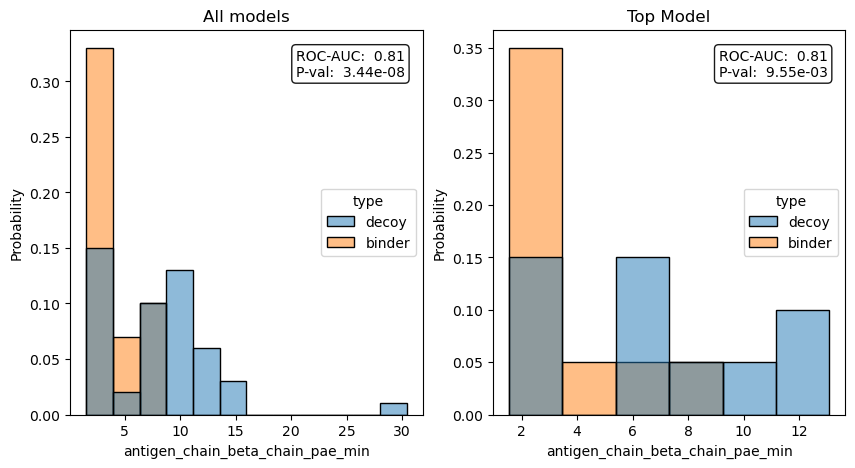

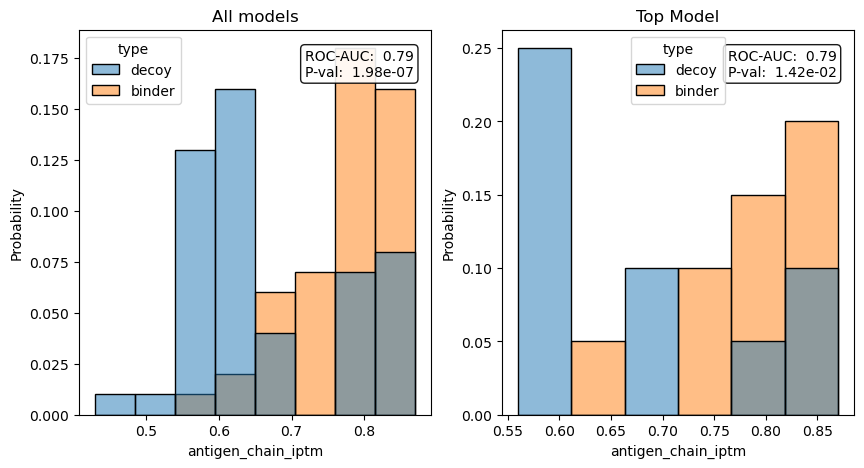

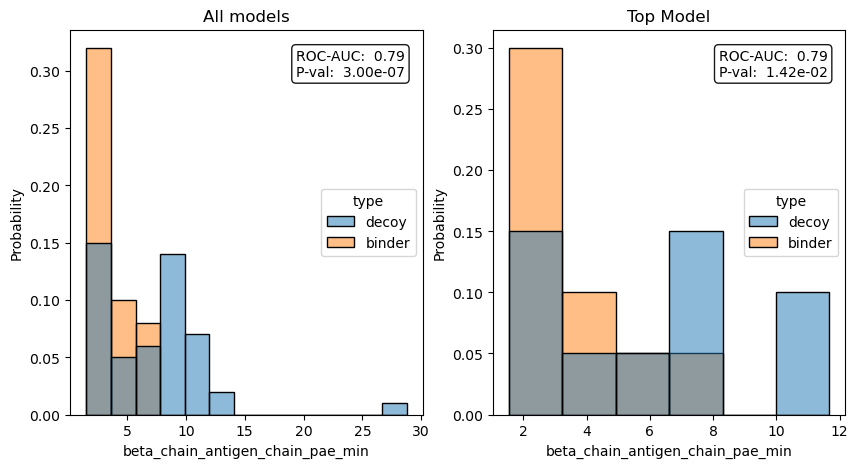

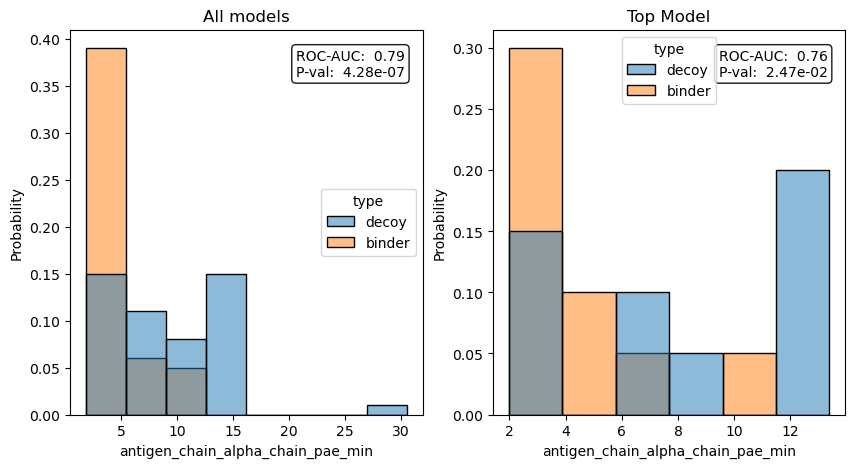

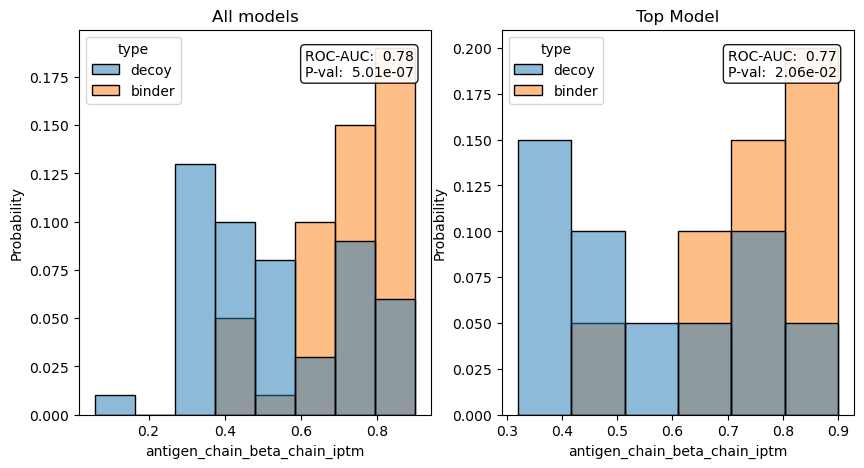

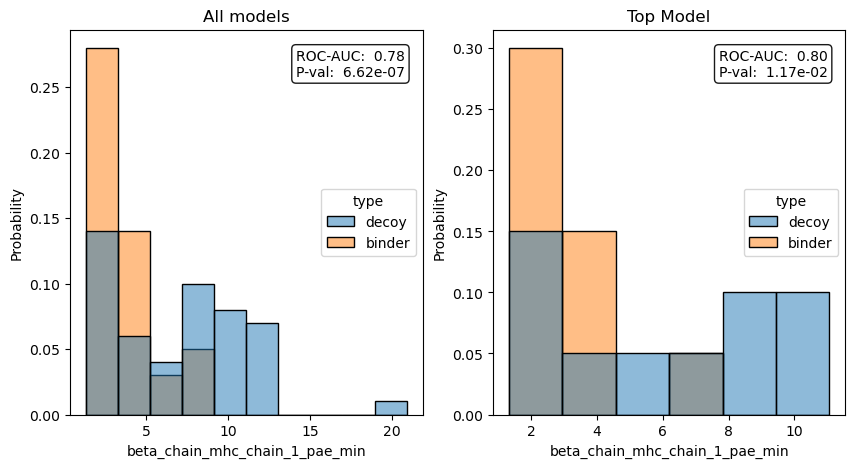

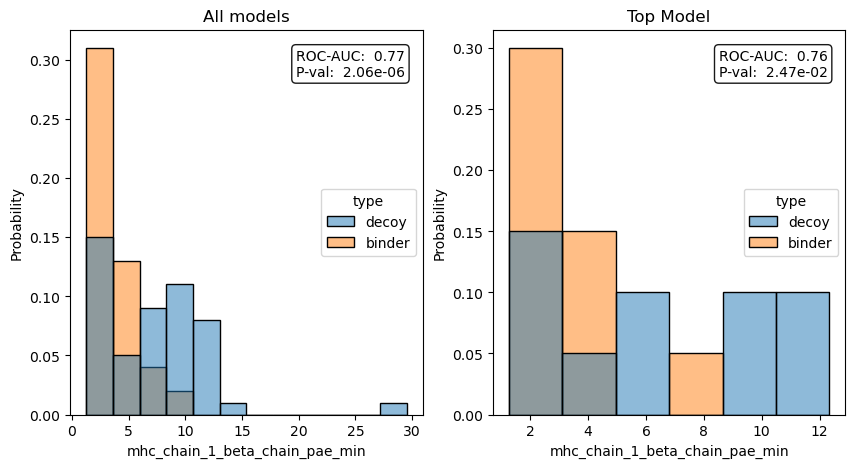

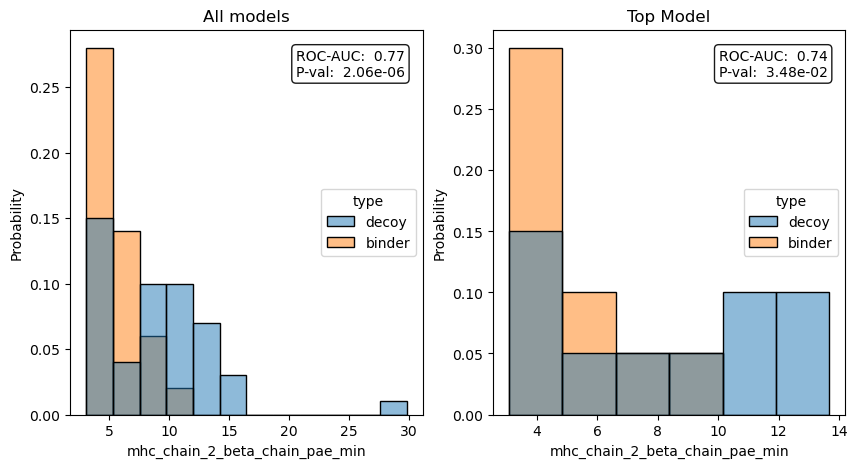

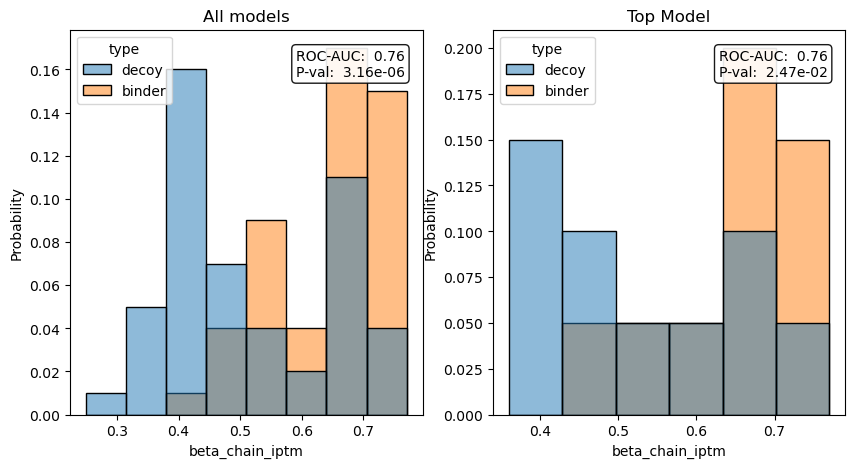

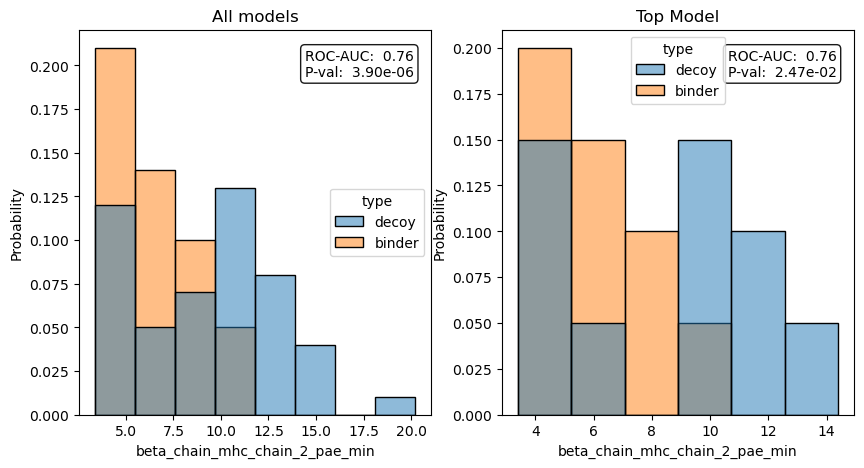

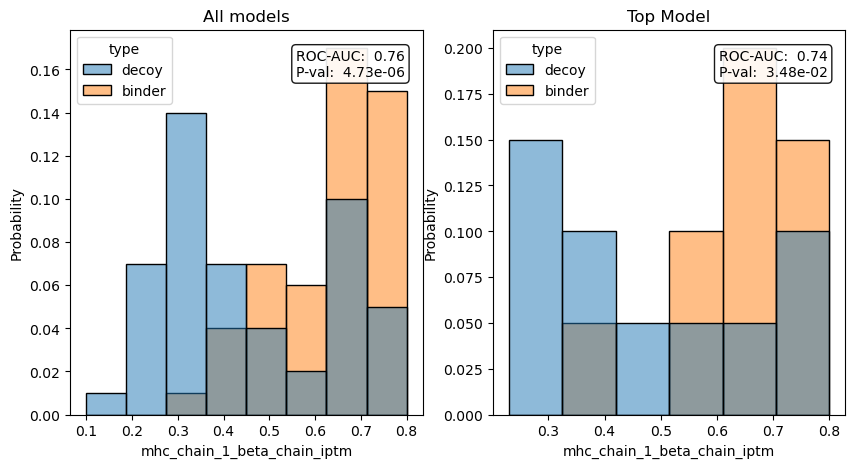

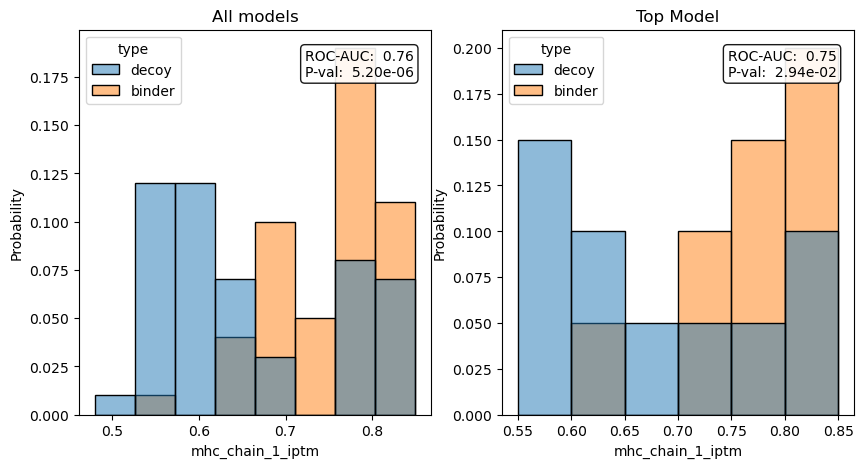

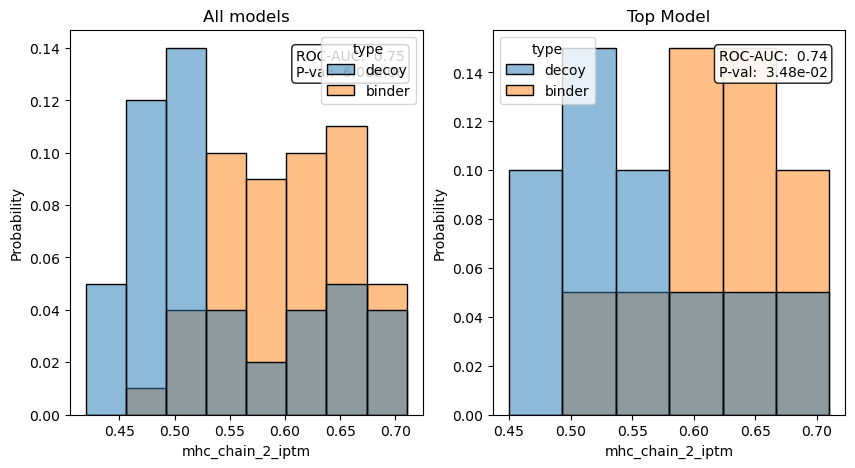

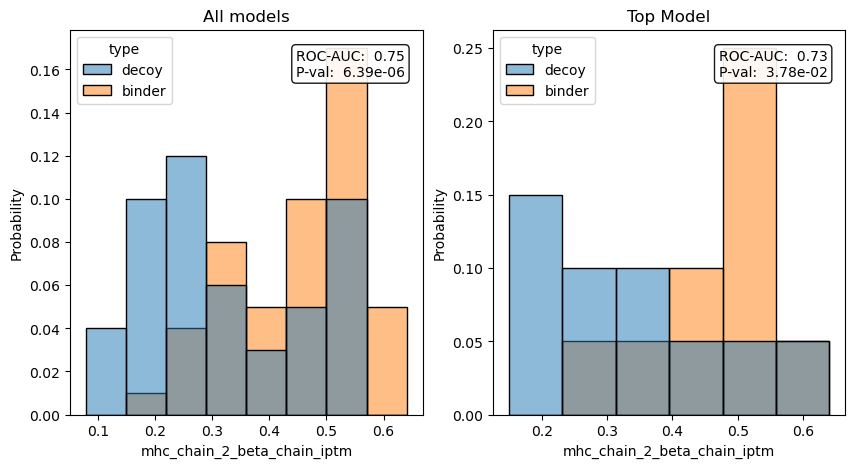

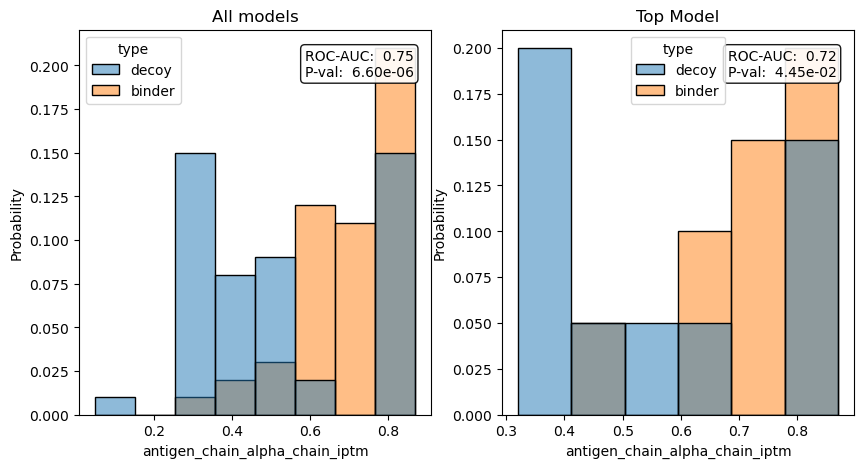

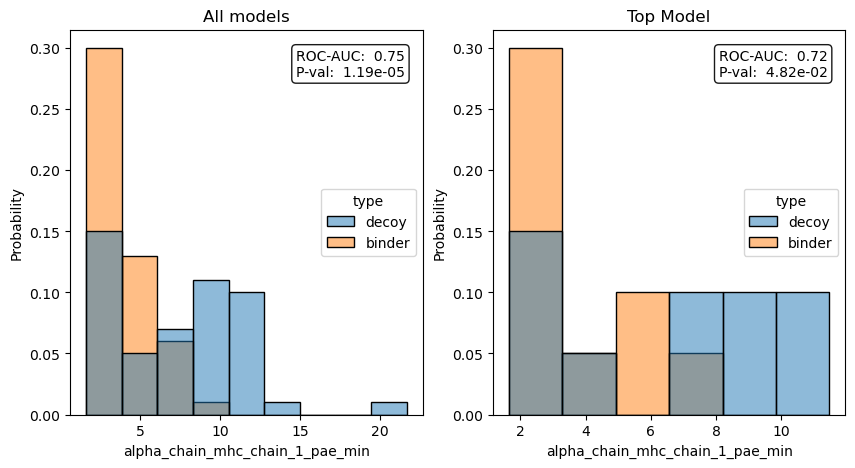

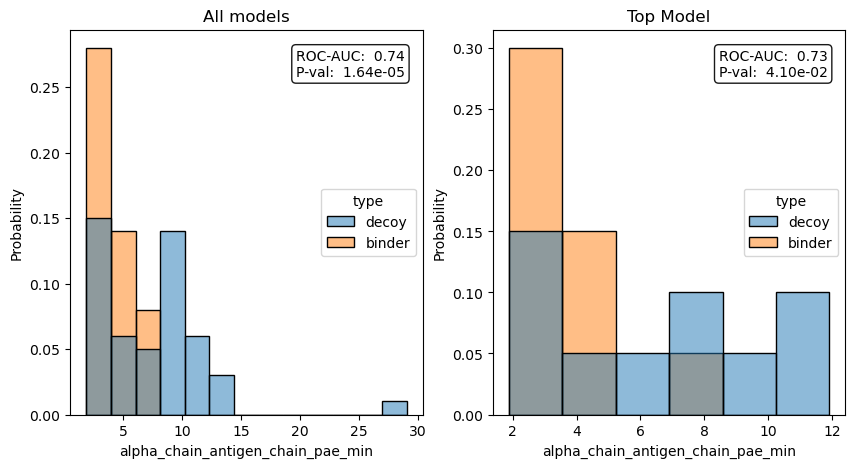

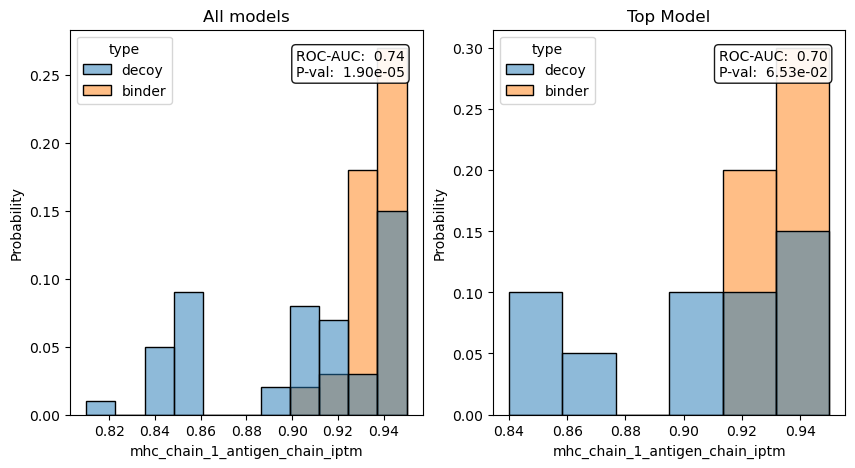

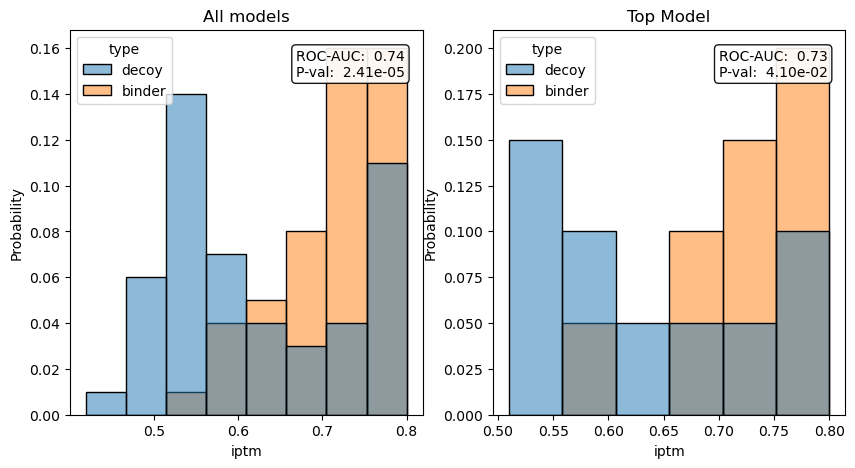

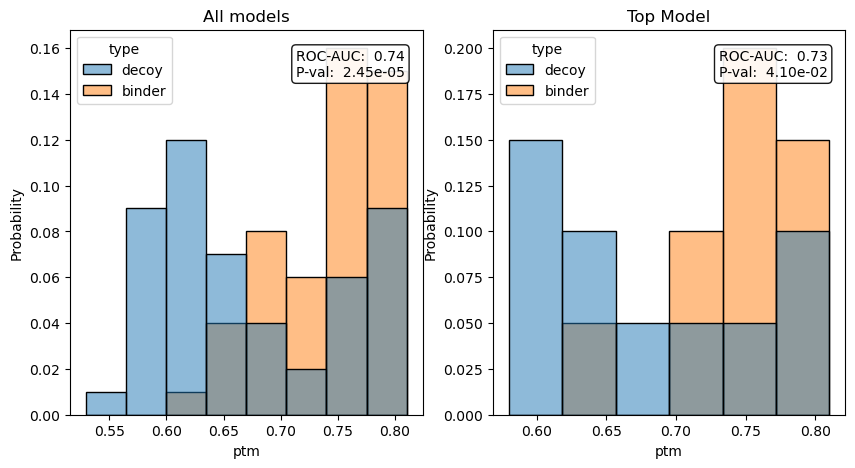

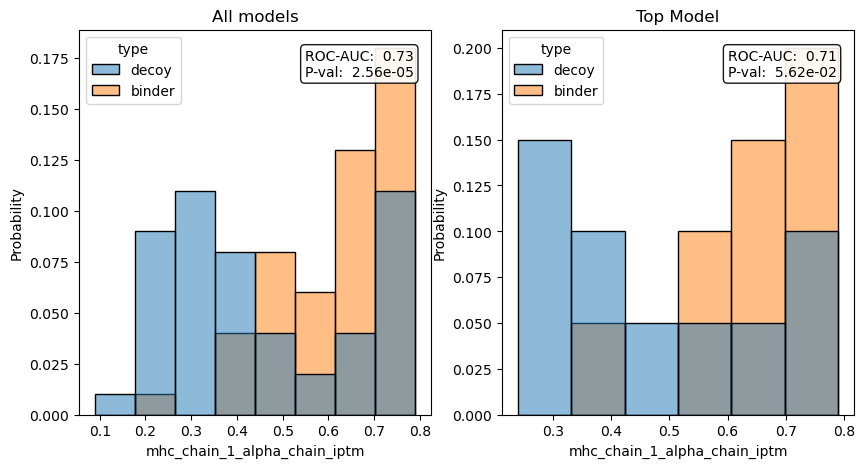

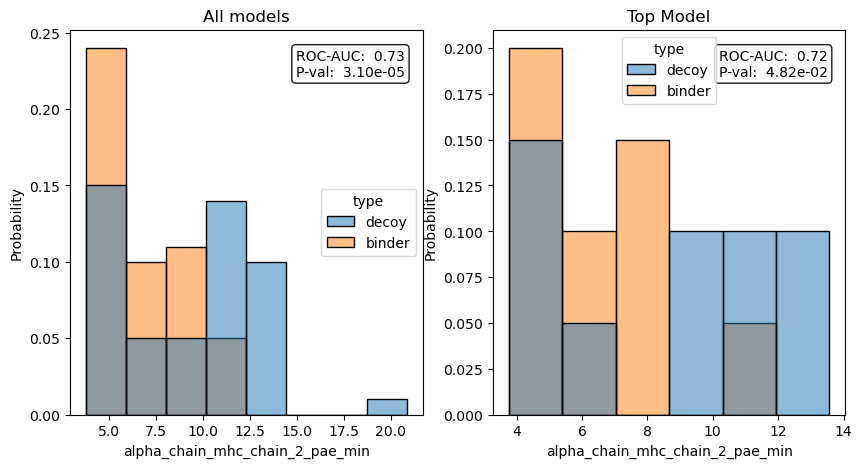

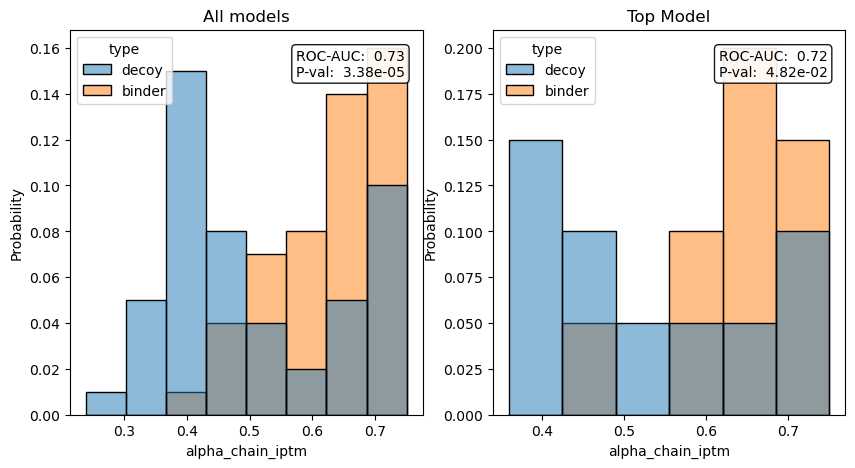

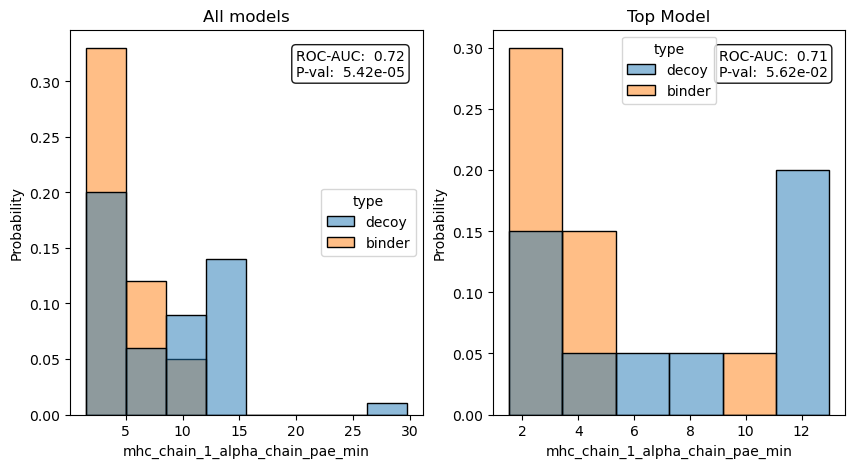

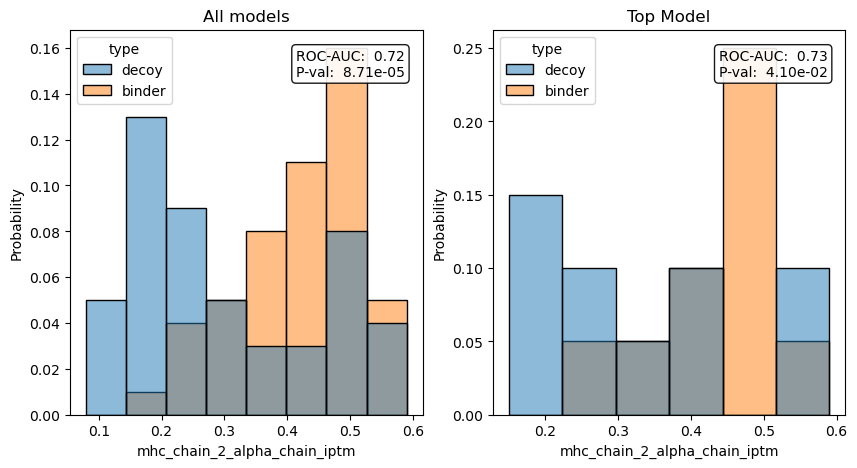

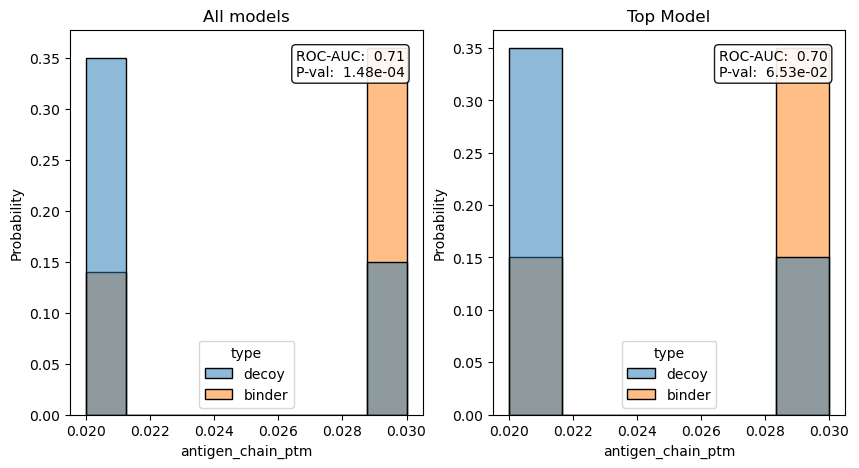

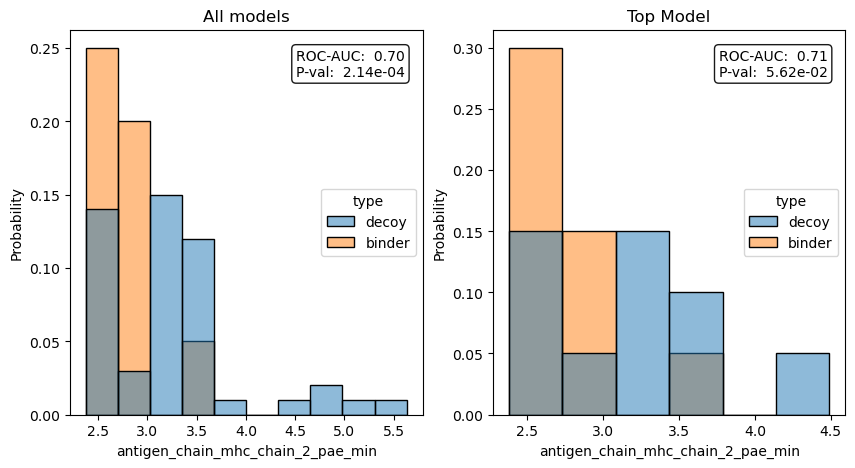

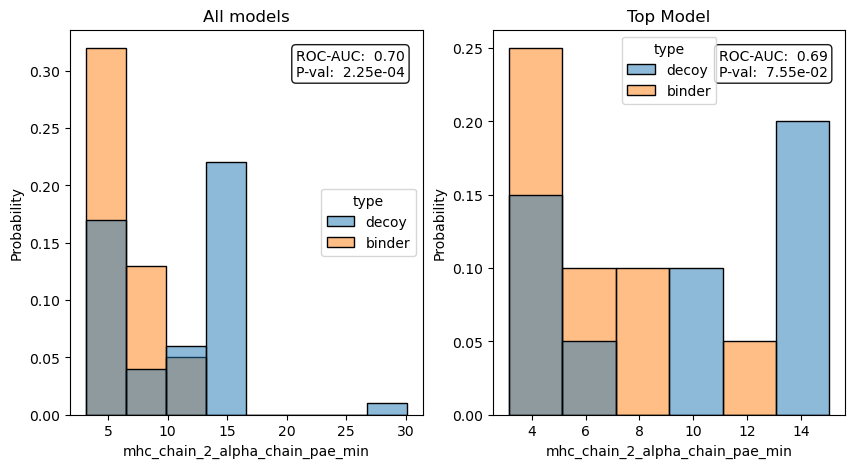

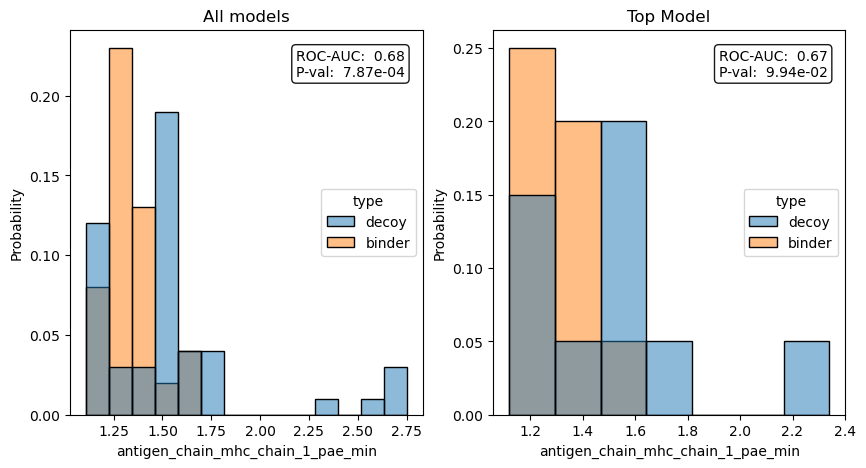

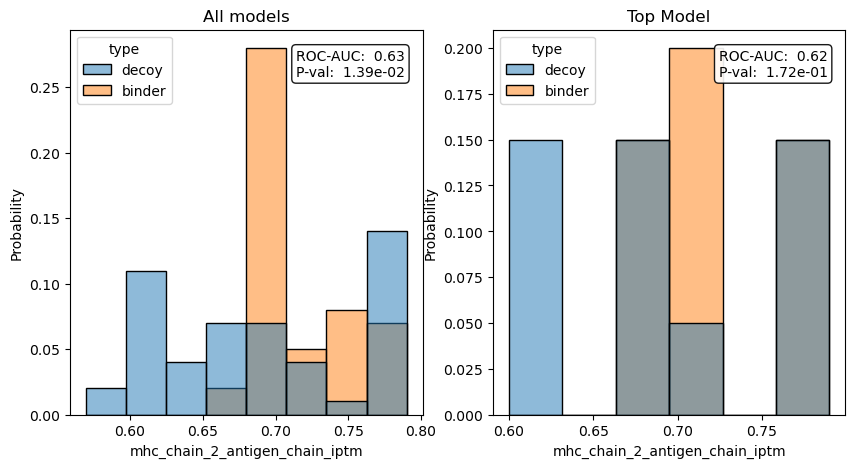

In [8]:
for column_name, row in (
    scores_summary.sort_values('roc_all_models', ascending=False).query('p_val_all_models < 0.05').iterrows()
):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

    # All Models
    sns.histplot(af3_scores, x=column_name, hue='type', stat='probability', ax=ax1)
    ax1.set_title('All models')
    ax1.text(
        0.95,
        0.95,
        f"ROC-AUC: {row['roc_all_models']: .2f}\nP-val: {row['p_val_all_models']: .2e}",
        transform=ax1.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )

    # Top Model
    sns.histplot(af3_scores.query('top_model'), x=column_name, hue='type', stat='probability', ax=ax2)
    ax2.text(
        0.95,
        0.95,
        f"ROC-AUC: {row['roc_top_model']: .2f}\nP-val: {row['p_val_top_model']: .2e}",
        transform=ax2.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )
    ax2.set_title('Top Model')

    plt.show()

In [9]:
af3_scores['combined_iptm'] = af3_scores.filter(regex='(antigen_chain|mhc_chain_1)_(alpha|beta)_chain_iptm').apply(
    'mean', axis=1
)

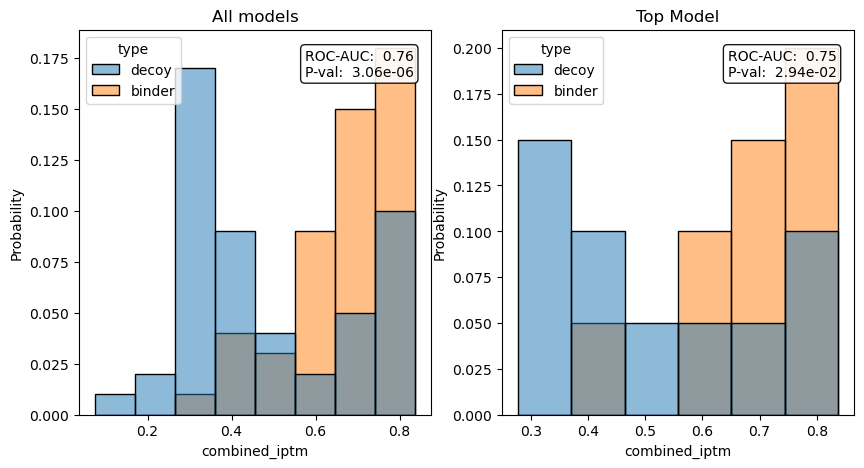

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

roc = roc_auc_score(af3_scores['label'], af3_scores['combined_iptm'])
stat, p_val = ranksums(
    af3_scores.query("type == 'binder'")['combined_iptm'],
    af3_scores.query("type == 'decoy'")['combined_iptm'],
    alternative='greater',
)

sns.histplot(af3_scores, x='combined_iptm', hue='type', stat='probability', ax=ax1)
ax1.set_title('All models')
ax1.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax1.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)

# Top Model
roc = roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')['combined_iptm'])
stat, p_val = ranksums(
    af3_scores.query("top_model and type == 'binder'")['combined_iptm'],
    af3_scores.query("top_model and type == 'decoy'")['combined_iptm'],
    alternative='greater',
)

ax2.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax2.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)
sns.histplot(af3_scores.query('top_model'), x='combined_iptm', hue='type', stat='probability', ax=ax2)
ax2.set_title('Top Model')

plt.show()

In [11]:
af3_scores['combined_pae_min'] = af3_scores.filter(
    regex=(
        '((antigen_chain|mhc_chain_1)_(alpha_chain|beta_chain))'
        '|((alpha_chain|beta_chain)_(antigen_chain|mhc_chain_1))_pae_min'
    )
).apply('mean', axis=1)

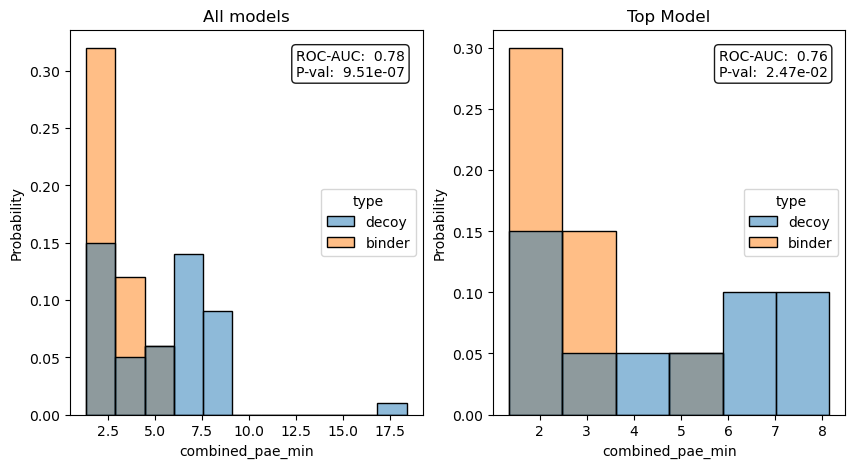

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

roc = 1 - roc_auc_score(af3_scores['label'], af3_scores['combined_pae_min'])
stat, p_val = ranksums(
    af3_scores.query("type == 'binder'")['combined_pae_min'],
    af3_scores.query("type == 'decoy'")['combined_pae_min'],
    alternative='less',
)

sns.histplot(af3_scores, x='combined_pae_min', hue='type', stat='probability', ax=ax1)
ax1.set_title('All models')
ax1.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax1.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)

# Top Model
roc = 1 - roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')['combined_pae_min'])
stat, p_val = ranksums(
    af3_scores.query("top_model and type == 'binder'")['combined_pae_min'],
    af3_scores.query("top_model and type == 'decoy'")['combined_pae_min'],
    alternative='less',
)

ax2.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax2.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)
sns.histplot(af3_scores.query('top_model'), x='combined_pae_min', hue='type', stat='probability', ax=ax2)
ax2.set_title('Top Model')

plt.show()

## PAE Based specificity

In [13]:
pae_scores = []

for path in (
    path
    for path in glob.glob('../data/interim/structures-af3/*/seed-*_sample-*/*_confidences.json')
    if 'summary' not in os.path.basename(path)
):
    with open(path, 'r') as fh:
        confidence = json.load(fh)

    name = re.match(
        r'(?P<structure_name>\d+(?:_\d+)?)_seed-(?P<seed>\d+)_sample-(?P<sample>\d+)_confidences.json',
        os.path.basename(path),
    )

    pae_score = {**name.groupdict()}

    pae_numbering = [
        (idx, (chain_id, res_seq_id))
        for idx, (chain_id, res_seq_id) in enumerate(
            zip(confidence['token_chain_ids'], confidence['token_res_ids'], strict=True)
        )
    ]

    tcr_idxs = np.array([idx for idx, (chain_id, _) in pae_numbering if chain_id in ('D', 'E')])
    pmhc_idxs = np.array([idx for idx, (chain_id, _) in pae_numbering if chain_id in ('A', 'C')])

    pae_score['tcr_pmhc_pae_score'] = np.mean(np.array(confidence['pae'])[np.ix_(tcr_idxs, pmhc_idxs)])

    pae_scores.append(pae_score)

pae_scores = pd.DataFrame(pae_scores)

In [14]:
af3_scores = af3_scores.merge(pae_scores, how='inner', on=['structure_name', 'seed', 'sample'])

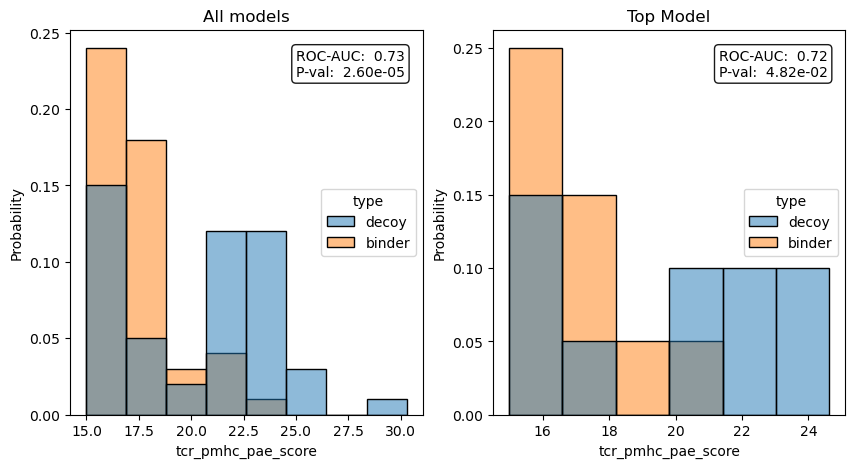

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

roc = 1 - roc_auc_score(af3_scores['label'], af3_scores['tcr_pmhc_pae_score'])
stat, p_val = ranksums(
    af3_scores.query("type == 'binder'")['tcr_pmhc_pae_score'],
    af3_scores.query("type == 'decoy'")['tcr_pmhc_pae_score'],
    alternative='less',
)

sns.histplot(af3_scores, x='tcr_pmhc_pae_score', hue='type', stat='probability', ax=ax1)
ax1.set_title('All models')
ax1.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax1.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)

# Top Model
roc = 1 - roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')['tcr_pmhc_pae_score'])
stat, p_val = ranksums(
    af3_scores.query("top_model and type == 'binder'")['tcr_pmhc_pae_score'],
    af3_scores.query("top_model and type == 'decoy'")['tcr_pmhc_pae_score'],
    alternative='less',
)

ax2.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax2.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)
sns.histplot(af3_scores.query('top_model'), x='tcr_pmhc_pae_score', hue='type', stat='probability', ax=ax2)
ax2.set_title('Top Model')

plt.show()

In [16]:
specific_pae_scores = []

for path in (
    path
    for path in glob.glob('../data/interim/structures-af3/*/seed-*_sample-*/*_confidences.json')
    if 'summary' not in os.path.basename(path)
):
    # Load raw confidence data
    with open(path, 'r') as fh:
        confidence = json.load(fh)

    name = re.match(
        r'(?P<structure_name>\d+(?:_\d+)?)_seed-(?P<seed>\d+)_sample-(?P<sample>\d+)_confidences.json',
        os.path.basename(path),
    )

    pae_score = {**name.groupdict()}

    pae_numbering = [
        (idx, (chain_id, res_seq_id))
        for idx, (chain_id, res_seq_id) in enumerate(
            zip(confidence['token_chain_ids'], confidence['token_res_ids'], strict=True)
        )
    ]

    # Load sequence information
    with open(glob.glob(os.path.join(os.path.dirname(os.path.dirname(path)), '*_data.json'))[0], 'r') as fh:
        input_data = json.load(fh)

    input_sequences = {
        sequence_info['protein']['id']: sequence_info['protein']['sequence']
        for sequence_info in input_data['sequences']
    }

    # Number sequences using ANARCI
    numbered_sequences = {}
    for chain_id, sequence in input_sequences.items():
        try:
            numbered_sequence, chain_type = anarci.number(sequence)

        except:  # noqa: E722 Anarci throws exception on B2M
            numbered_sequence = None
            chain_type = None

        if numbered_sequence:
            numbered_sequences[chain_id] = [(seq_id, olc) for seq_id, olc in numbered_sequence if olc != '-']

        else:
            numbered_sequences[chain_id] = [((res_id, ' '), olc) for res_id, olc in enumerate(sequence, 1)]

    # Calculate offset between anarci sequence and input sequences
    offsets = {
        chain_id: sequence.find(''.join([olc for _, olc in numbered_sequences[chain_id]]))
        for chain_id, sequence in input_sequences.items()
    }

    # Get relevant ranges for input sequences
    relative_ranges = {
        chain_id: tuple(
            [
                idx + offsets[chain_id]
                for idx, ((seq_id, _), _) in enumerate(numbered_sequences[chain_id])
                if seq_id in IMGT_CDR
            ]
        )
        for chain_id in ('D', 'E')
    }

    if max([seq_id for (seq_id, _), _ in numbered_sequences['A']]) > MHC_I_IMGT_BETA_HELIX_START:
        tcr_contact_positions = []

        for helix in IMGT_MHC_TCR_CONTACT_POSITIONS:
            offset = MHC_I_IMGT_BETA_HELIX_START if helix == 'beta' else 0

            for res_id in IMGT_MHC_TCR_CONTACT_POSITIONS[helix]:
                seq_id = int(''.join([char for char in res_id if char.isnumeric()])) + offset
                insert_code = (
                    ''.join(
                        [char for char in res_id if not char.isnumeric()],
                    )
                    if len([char for char in res_id if not char.isnumeric()]) > 0
                    else ' '
                )

                tcr_contact_positions.append((seq_id, insert_code))

        tcr_contact_positions = set(tcr_contact_positions)

        relative_ranges['A'] = tuple(
            [
                idx + offsets['A']
                for idx, (res_id, _) in enumerate(numbered_sequences['A'])
                if res_id in tcr_contact_positions
            ]
        )
        relative_ranges['B'] = None

    else:
        tcr_contact_positions = {'A': [], 'B': []}

        for helix in IMGT_MHC_TCR_CONTACT_POSITIONS:
            for res_id in IMGT_MHC_TCR_CONTACT_POSITIONS[helix]:
                seq_id = int(''.join([char for char in res_id if char.isnumeric()]))
                insert_code = (
                    ''.join(
                        [char for char in res_id if not char.isnumeric()],
                    )
                    if len([char for char in res_id if not char.isnumeric()]) > 0
                    else ' '
                )

                tcr_contact_positions['A' if helix == 'alpha' else 'B'].append((seq_id, insert_code))

        relative_ranges['A'] = tuple(
            [
                idx + offsets['A']
                for idx, (res_id, _) in enumerate(numbered_sequences['A'])
                if res_id in tcr_contact_positions['A']
            ]
        )

        relative_ranges['B'] = tuple(
            [
                idx + offsets['B']
                for idx, (res_id, _) in enumerate(numbered_sequences['B'])
                if res_id in tcr_contact_positions['B']
            ]
        )

    relative_ranges['C'] = [idx + offsets['C'] for idx, _ in enumerate(numbered_sequences['C'])]

    # Translate ranges to concatenated PAE space
    current_chain = None
    relative_offset = {}

    for pae_idx, (chain_id, _) in pae_numbering:
        if chain_id != current_chain:
            relative_offset[chain_id] = pae_idx
            current_chain = chain_id

    ranges = {
        chain_id: [idx + relative_offset[chain_id] for idx in relative_range]
        for chain_id, relative_range in relative_ranges.items()
        if relative_range is not None
    }

    # Get PAE values and average
    tcr_idxs = np.array([idx for chain_id, range_ in ranges.items() for idx in range_ if chain_id in ('D', 'E')])
    pmhc_idxs = np.array([idx for chain_id, range_ in ranges.items() for idx in range_ if chain_id not in ('D', 'E')])

    pae_score['cdr_pmhc_pae_score'] = np.mean(np.array(confidence['pae'])[np.ix_(tcr_idxs, pmhc_idxs)])

    specific_pae_scores.append(pae_score)

specific_pae_scores = pd.DataFrame(specific_pae_scores)

Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really went wrong that has not been handled
'C'
Error: Something really w

In [17]:
af3_scores = af3_scores.merge(specific_pae_scores, how='inner', on=['structure_name', 'seed', 'sample'])

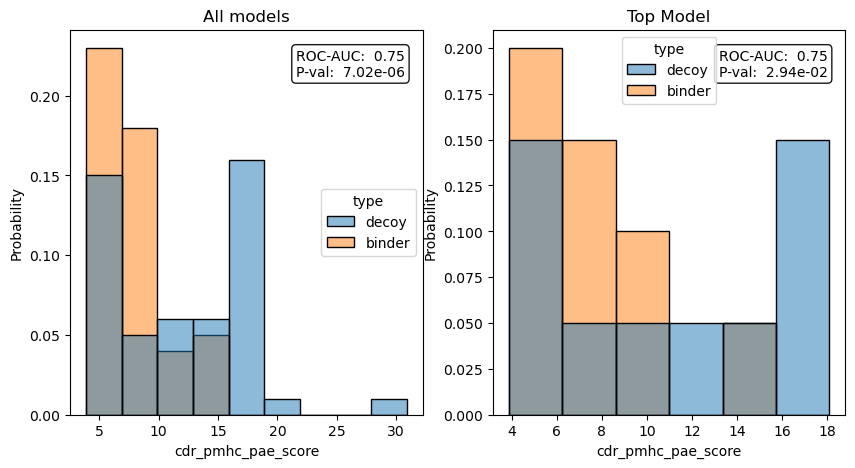

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

roc = 1 - roc_auc_score(af3_scores['label'], af3_scores['cdr_pmhc_pae_score'])
stat, p_val = ranksums(
    af3_scores.query("type == 'binder'")['cdr_pmhc_pae_score'],
    af3_scores.query("type == 'decoy'")['cdr_pmhc_pae_score'],
    alternative='less',
)

sns.histplot(af3_scores, x='cdr_pmhc_pae_score', hue='type', stat='probability', ax=ax1)
ax1.set_title('All models')
ax1.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax1.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)

# Top Model
roc = 1 - roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')['cdr_pmhc_pae_score'])
stat, p_val = ranksums(
    af3_scores.query("top_model and type == 'binder'")['cdr_pmhc_pae_score'],
    af3_scores.query("top_model and type == 'decoy'")['cdr_pmhc_pae_score'],
    alternative='less',
)

ax2.text(
    0.95,
    0.95,
    f'ROC-AUC: {roc: .2f}\nP-val: {p_val: .2e}',
    transform=ax2.transAxes,
    verticalalignment='top',
    horizontalalignment='right',
    bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
)
sns.histplot(af3_scores.query('top_model'), x='cdr_pmhc_pae_score', hue='type', stat='probability', ax=ax2)
ax2.set_title('Top Model')

plt.show()